# Этап 09. Количественная оценка экономической кластеризации

## 1. Цель и место в исследовании

**Цель** — сопоставить сохранённые месячные разбиения муниципалитетов по геометрическому качеству, графовой структуре и временной согласованности. Кластеризация повторно **не выполняется**.

Из этапа 05 берутся месячные CLR-признаки шести потребительских долей; из этапа 06 — взвешенные графы CLR + union kNN; из этапа 07 — готовые метки K-Means, Spectral и Leiden и оценки повторных запусков. Сохранённая временная модель этапа 08 добавляется **только при наличии её проверенных меток и манифеста с выбранной** $\lambda$. 

Единица сравнения — одна и та же совокупность $n=2016$ муниципалитетов в одном и том же месяце $t$. На каждом $t$ внутренние геометрические индексы вычисляются **на одинаковом** $X_t^{\mathrm{CLR}}\in\mathbb R^{n\times6}$, а графовые — на одинаковом $W_t$. Номера кластеров сами по себе не имеют числового смысла.

## 2. Конкурсные ICVI: принятые определения

| Показатель | Полное название | Пространство | Направление |
|---|---|---|---|
| **SW** | Silhouette Width | Месячные CLR-признаки | Максимум |
| **CH** | Calinski–Harabasz Index | Месячные CLR-признаки | Максимум |
| **S_Dbw** | Scatter–Density between (вариант Halkidi) | Месячные CLR-признаки | Минимум |
| **AVI** | Average Isolability | Бинарная структура экономической сети | Максимум |
| **AVU** | Average Unifiability | Бинарная структура экономической сети | Минимум |
| **MQ** | Modularity Quality, **в принятой здесь трактовке** Modularity $Q$ Ньюмана–Гирвана | Взвешенная экономическая сеть | Максимум |

Определения AVI и AVU взяты из статьи [Shalileh, Antonov, Tsyplakova, *Cluster Validity across Attribute and Network Spaces*, Doklady Mathematics, DOI:10.1134/S1064562425700589](https://doi.org/10.1134/S1064562425700589), формулы (18)–(21). Для них применяется именно бинарная матрица смежности, как в первоисточнике, а не произвольное взвешенное обобщение.

**Рабочая трактовка MQ:** по согласованному решению проекта под этим обозначением понимаем классическую **взвешенную модулярность $Q$**. Это тот же показатель, который уже рассчитан как `modularity`: столбец `mq` является его явным синонимом, а не новой независимо рассчитанной метрикой. В других работах MQ может означать иную функцию качества (например, Modularization Quality), поэтому без официального конкурсного определения полную эквивалентность терминов подтверждать нельзя.

**Принцип сравнимости:** геометрические и графовые критерии не сводятся к единому арифметическому среднему. Число кластеров $K$ влияет на уровни AVI и AVU и учитывается при интерпретации.

## 3. Метрики геометрической компактности и разделимости

Обозначим $C_{a,t}$ — множество муниципалитетов кластера $a$ в месяце $t$, $K_t$ — число кластеров, $x_{i,t}\in\mathbb R^6$ — CLR-признаки, $\mu_{a,t}$ — центроид, $\mu_t$ — общая средняя точка. Здесь и далее формулы записаны для фиксированного месяца, индекс $t$ опущен там, где это не создаёт неоднозначности.

**SW — Silhouette Width (максимизируется):**

$$
s(i)=\frac{b(i)-a(i)}{\max\{a(i),b(i)\}},\qquad
\mathrm{SW}=\frac1n\sum_{i=1}^n s(i),
$$

где $a(i)$ — среднее евклидово расстояние от $i$ до иных объектов своего кластера, $b(i)$ — минимум средних расстояний от $i$ до объектов иного кластера. Для одиночных кластеров реализация `scikit-learn` задаёт $s(i)=0$; это учитывается при оценке неоднородных разбиений. Метрика определена при $2\le K<n$, имеет диапазон $[-1,1]$; максимум предпочтительнее.

**CH — Calinski–Harabasz Index (максимизируется):**

$$
B=\sum_{a=1}^K |C_a|\lVert\mu_a-\mu\rVert_2^2,\qquad
W=\sum_{a=1}^K\sum_{i\in C_a}\lVert x_i-\mu_a\rVert_2^2,
$$
$$
\mathrm{CH}=\frac{B/(K-1)}{W/(n-K)}.
$$

$B$ — межкластерная, $W$ — внутрикластерная сумма квадратов. Для вырожденного $W=0$ индекс требует особого обращения; используем проверенную реализацию `scikit-learn`. CH зависит от числа объектов и числа кластеров, поэтому без поправок не универсален для разных выборок. **Здесь все модели оцениваются на одинаковых $n$ и $X_t$.**

## 4. Индекс S_Dbw: зафиксированный вариант и ограничения

Рассчитывается вариант Halkidi для евклидовой геометрии месячного CLR-пространства:

$$
\mathrm{S\_Dbw}=\mathrm{Scatt}+\mathrm{Dens}_{bw},\qquad\text{минимизируется},
$$
$$
\mathrm{Scatt}=\frac1K\sum_{a=1}^K\frac{\lVert v_a\rVert_2}{\lVert v\rVert_2},\qquad
r=\frac1K\sqrt{\sum_{a=1}^K\lVert v_a\rVert_2},
$$

где $v_a=\operatorname{Var}(X_{C_a})$ — вектор дисперсий по координатам внутри кластера, $v=\operatorname{Var}(X)$ — вектор дисперсий всех объектов, $r$ — радиус оценки плотности. В реализации используется `ddof=0`.

Определим $D_a(z)=\sum_{i\in C_a}\mathbf1\{\lVert x_i-z\rVert_2\le r\}$ и $m_{ab}=(\mu_a+\mu_b)/2$. Тогда

$$
\mathrm{Dens}_{bw}=\frac{1}{K(K-1)}\sum_{a\ne b}
\frac{D_a(m_{ab})+D_b(m_{ab})}{\max\{D_a(\mu_a),D_b(\mu_b)\}}.
$$

Меньшее значение соответствует более компактным кластерам с меньшей межкластерной плотностью. **Ограничения:** разные определения $r$ и центров дают разные численные варианты S_Dbw; при нулевой общей дисперсии, нулевом радиусе либо нулевом знаменателе возвращается `NaN`, а не придуманное число. S_Dbw чувствителен к числу и размерам кластеров; одиночные сообщества требуют осторожной интерпретации. Реализация: `src.cluster_validation.s_dbw_halkidi`, тесты — `tests/test_cluster_validation.py`.

## 5. Качество графа и временная согласованность

Для симметричной матрицы неотрицательных весов $A=(w_{ij})$, взвешенных степеней $d_i=\sum_jw_{ij}$ и $2m=\sum_i d_i$:

$$
Q=\frac{1}{2m}\sum_{i,j}
\left(w_{ij}-\frac{d_i d_j}{2m}\right)
\mathbf1\{g_i=g_j\}.
$$

**Modularity $Q$** максимизируется; она измеряет избыток внутрикластерной связности относительно конфигурационной нулевой модели. В данном проекте этот показатель принят в качестве **MQ (Modularity Quality)**. Поле `mq` численно тождественно `modularity`; используется реализация этапа 07 на том же $W_t$.

**ARI** — Adjusted Rand Index, сравнение разбиений соседних месяцев, инвариантное к перестановкам номеров кластеров:

$$
\mathrm{ARI}=\frac{\mathrm{RI}-\mathbb E[\mathrm{RI}]}{1-\mathbb E[\mathrm{RI}]},
$$

где $\mathrm{RI}$ — доля согласованно классифицированных пар муниципалитетов, поправка относится к случайным разбиениям с фиксированными размерами кластеров. Максимум $1$; случайная согласованность около $0$.

**NMI** — Normalized Mutual Information:

$$
\mathrm{NMI}(U,V)=\frac{2I(U;V)}{H(U)+H(V)},\quad
I(U;V)=\sum_{a,b}p_{ab}\log\frac{p_{ab}}{p_a p_b},
$$

где $p_{ab}$ — доля объектов на пересечении кластеров $a$ и $b$, $p_a,p_b$ — маргинальные доли, $H$ — энтропия разбиения. NMI максимизируется; в отличие от ARI, не корректируется на случайное согласие.

**Отдельный показатель:** `ari_repeats` — устойчивость к разным `random_state` из сохранённой таблицы этапа 07, а `ari_prev` и `nmi_prev` — согласие **соседних месяцев**, не качество отдельных кластеров. Никаких арифметических средних между SW, CH, $Q$, ARI и NMI не берётся.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.feature_analysis import parse_dynamic_columns
from src.cluster_models import read_graph_sequence
from src.cluster_validation import (
    load_saved_partitions, evaluate_all, merge_repeatability, monthly_summary,
    plot_quality_pairs, save_metrics
)

cfg = json.loads((ROOT/'configs'/'clustering_experiment.json').read_text(encoding='utf-8'))
vcfg = cfg['validation_09']
X_dynamic = pd.read_parquet(ROOT/cfg['feature_path'])
mapping = parse_dynamic_columns(X_dynamic)
months = [str(p) for p in sorted({p for p, _ in mapping})]
assert len(months) == 24 and len(X_dynamic) == 2016

graphs = read_graph_sequence(ROOT/cfg['graph_directory'], X_dynamic.index, months)
manifest = json.loads((ROOT/cfg['graph_directory']/'manifest.json').read_text(encoding='utf-8'))
if not all(manifest.get(key) == value for key,value in {
    'method':'union', 'k':10, 'representation':'clr', 'window':1
}.items()):
    raise ValueError('Этот этап ожидает выбранные CLR + union kNN, k=10, окно=1; проверьте manifest.json')
print('Данные:', X_dynamic.shape, '| графов:', len(graphs), '| период:',months[0], '—',months[-1])

Данные: (2016, 144) | графов: 24 | период: 2023-01 — 2024-12


## 6. Загрузка ранее сохранённых разбиений

Не создаём заново K-Means, Leiden или Spectral. Из `outputs/bdmo_v3/clustering_step07/` читаем `labels.parquet`, `metrics.parquet` и `experiment.json`. При наличии полноценного набора этапа 08 с `temporal_labels.parquet` и `temporal_experiment.json` добавляем временно-регуляризованное разбиение как четвёртую модель. Если его ещё не сохранили, три основных метода всё равно оцениваются; это будет явно показано, а не замаскировано повторным запуском алгоритма.

In [2]:
stage07 = ROOT / cfg['output_directory']
stage08 = ROOT / cfg['temporal_08']['output_directory']
partitions, temporal_info = load_saved_partitions(
    stage07, stage08, X_dynamic.index, months,
    include_temporal=vcfg['include_temporal_if_saved']
)
parameters = json.loads((stage07/'experiment.json').read_text(encoding='utf-8'))['selected_parameters']
print('Загруженные методы:', list(partitions))
print('Параметры из этапа 07:', parameters)
print('Временная модель:', temporal_info)
display(pd.DataFrame([
    {'method':m, 'municipalities':len(v), 'months':len(v.columns),
     'clusters_first_month':v.iloc[:,0].nunique()}
    for m,v in partitions.items()
]))

Загруженные методы: ['kmeans', 'spectral', 'leiden']
Параметры из этапа 07: {'kmeans': 4.0, 'leiden': 0.3, 'spectral': 4.0}
Временная модель: {'temporal_status': 'not_saved', 'temporal_selected_lambda': None}


,method,municipalities,months,clusters_first_month
0,kmeans,2016,24,4
1,spectral,2016,24,4
2,leiden,2016,24,9


## 7. Единый расчёт по 24 месяцам

SW и CH считаются через `scikit-learn`, S_Dbw — собственной проверяемой функцией зафиксированного варианта, графовая модулярность — кодом этапа 07. **SW здесь вычисляется точно на всех 2016 объектах** (в отличие от прежней контрольной подвыборки в шаге 07), поэтому цифры могут отличаться от ранее опубликованного Silhouette.

Если разбиение вырождено, геометрические индексы остаются `NaN` со статусом; такие месяцы нельзя исключать молча. После основного расчёта AVI/AVU/MQ добавляются отдельной лёгкой ячейкой без повторного вычисления SW, CH и S_Dbw. Новые значения ещё не присутствуют в старых сохранённых outputs до выполнения этой ячейки.

In [3]:
metrics09 = evaluate_all(
    X_dynamic, mapping, months, graphs, partitions,
    zero_floor=cfg['zero_floor'],
    method_params=parameters,
    temporal_lambda=temporal_info['temporal_selected_lambda']
)
metrics09 = merge_repeatability(metrics09, stage07, parameters)
print('Размер таблицы:',metrics09.shape, '| строки по методам:')
print(metrics09.groupby('method').size().to_string())
print('Статусы расчётов:')
display(metrics09.groupby(['method','status']).size().rename('months').reset_index())
display(metrics09[['month','method','n_clusters','sw','ch','s_dbw',
                   'modularity','ari_prev','nmi_prev','ari_repeats']].head(8).round(3))

Размер таблицы: (72, 19) | строки по методам:
method
kmeans      24
leiden      24
spectral    24
Статусы расчётов:


,method,status,months
0,kmeans,ok,24
1,leiden,ok,4
2,leiden,s_dbw_undefined,20
3,spectral,ok,16
4,spectral,s_dbw_undefined,8


,month,method,n_clusters,sw,ch,s_dbw,modularity,ari_prev,nmi_prev,ari_repeats
0,2023-01,kmeans,4,0.302,1243.765,0.848,0.624,NaN,NaN,0.980
1,2023-01,spectral,4,0.450,10.893,NaN,0.000,NaN,NaN,1.000
2,2023-01,leiden,9,0.179,359.180,NaN,0.709,NaN,NaN,0.802
3,2023-02,kmeans,4,0.314,1273.795,0.699,0.620,0.777,0.736,0.990
4,2023-02,spectral,4,0.364,484.479,0.343,0.458,0.011,0.051,0.958
5,2023-02,leiden,11,0.175,372.489,NaN,0.720,0.391,0.578,0.821
6,2023-03,kmeans,4,0.315,1301.310,0.650,0.614,0.796,0.747,1.000
7,2023-03,spectral,4,0.414,36.051,NaN,0.001,0.018,0.049,1.000


### 7.1. Графовые индексы AVI, AVU и MQ

Обозначим $a_{ij}=\mathbf1\{w_{ij}>0\}$ — **бинарное** наличие ребра экономического графа, $s_{ia}=\mathbf1\{g_i=a\}$ — принадлежность муниципалитета $i$ кластеру $a$, $K$ — число кластеров. Введём число ориентированно учитываемых связей между двумя кластерами

$$
B_{ab}=\sum_{i=1}^{n}\sum_{j=1}^{n}a_{ij}s_{ia}s_{jb},
\qquad E_a=\sum_{b\ne a}B_{ab}.
$$

В неориентированном графе $B_{aa}$ учитывает каждое внутреннее ребро дважды, а $B_{ab}=B_{ba}$ при $a\ne b$.

**AVI — Average Isolability (максимум):**

$$
I_a=\frac{B_{aa}}{B_{aa}+E_a},\qquad
\mathrm{AVI}=\frac1K\sum_{a=1}^K I_a.
$$

$I_a$ — доля инцидентных кластеру $a$ связей, остающихся внутри него. Чем выше AVI, тем сильнее изолированы сообщества. Если у кластера нет инцидентных рёбер, отношение $0/0$ не определено.

**AVU — Average Unifiability (минимум):**

$$
U_{ab}=\frac{B_{ab}}{E_a+E_b-B_{ab}},\quad a\ne b,\qquad
\mathrm{AVU}=\frac1K\sum_{a=1}^{K}\sum_{b\ne a}U_{ab}.
$$

$U_{ab}$ отражает относительную значимость связей между кластерами $a$ и $b$ среди их внешних связей. Формула нормируется на $K$, **а не на $K(K-1)$**, в точности как формула (21) первоисточника. При нулевом знаменателе значение отмечается `NaN`. Для двух кластеров при наличии межкластерных рёбер AVU тождественно равна 1, поэтому в таком случае индекс не различает варианты разбиения.

**MQ — принятая взвешенная Modularity $Q$ (максимум):**

$$
\mathrm{MQ}=Q=\frac{1}{2m}\sum_{i,j}
\left(w_{ij}-\frac{d_i d_j}{2m}\right)\mathbf1\{g_i=g_j\},
\quad d_i=\sum_j w_{ij},\quad 2m=\sum_i d_i.
$$

Таким образом, AVI и AVU оценивают **топологию наличия рёбер**, а MQ — **веса экономического сходства**. Они имеют разные шкалы и чувствительность к $K$; их значения сопоставляются по отдельности на одной и той же сети для всех алгоритмов. Реализация: `network_quality_indices()` и `add_network_indices()` из `src/cluster_validation.py`.

In [4]:
from src.cluster_validation import add_network_indices

metrics09 = add_network_indices(metrics09, graphs, partitions)
print('Расчёт AVI / AVU / MQ:', len(metrics09), 'разбиений')
print('MQ совпадает с исходной Modularity:',
      np.allclose(metrics09['mq'], metrics09['modularity'], equal_nan=True))
display(metrics09.groupby('method')[['avi', 'avu', 'mq']].agg(['median', 'min', 'max']).round(3))
display(metrics09[['month', 'method', 'n_clusters', 'avi', 'avu', 'mq']].head(8).round(3))

Расчёт AVI / AVU / MQ: 72 разбиений
MQ совпадает с исходной Modularity: True


avi                  avu                   mq              
         median    min    max median    min    max median    min    max
method                                                                 
kmeans    0.909  0.896  0.921  0.625  0.561  0.663  0.639  0.593  0.664
leiden    0.717  0.499  0.931  0.442  0.278  0.599  0.715  0.674  0.748
spectral  0.581  0.296  0.938  0.535  0.500  0.666  0.456  0.000  0.667

,month,method,n_clusters,avi,avu,mq
0,2023-01,kmeans,4,0.896,0.582,0.624
1,2023-01,spectral,4,0.298,0.524,0.000
2,2023-01,leiden,9,0.535,0.349,0.709
3,2023-02,kmeans,4,0.902,0.573,0.620
4,2023-02,spectral,4,0.531,0.500,0.458
5,2023-02,leiden,11,0.499,0.278,0.720
6,2023-03,kmeans,4,0.903,0.584,0.614
7,2023-03,spectral,4,0.551,0.502,0.001


## 8. Сводка по месяцам и крайние периоды

Сводка содержит медианы и межквартильные размахи (IQR), а также даты максимума/минимума по соответствующему направлению оптимизации. Для SW, CH и Modularity лучше больше; для S_Dbw — меньше. Различия между месяцами могут отражать изменения расходов, но сами по себе не доказывают экономическую причинность.

Для AVI и AVU дополнительно указывается число месяцев, в которых индекс математически определён. MQ повторяет существующую взвешенную Modularity.

In [5]:
summary09 = monthly_summary(metrics09)
selected = ['months','invalid_months','sw_median','sw_iqr','ch_median','ch_iqr',
            's_dbw_median','s_dbw_iqr','modularity_median','modularity_iqr',
            'ari_prev_median','nmi_prev_median','n_clusters_median','largest_cluster_share_median']
selected += [f'{m}_{field}' for m in ('avi', 'avu', 'mq')
             for field in ('median', 'iqr', 'n_defined')]
display(summary09[selected].round(3))
display(summary09[[c for c in summary09.columns
                   if c.endswith('_best_month') or c.endswith('_worst_month')]])

,months,invalid_months,sw_median,sw_iqr,ch_median,ch_iqr,s_dbw_median,s_dbw_iqr,modularity_median,modularity_iqr,...,largest_cluster_share_median,avi_median,avi_iqr,avi_n_defined,avu_median,avu_iqr,avu_n_defined,mq_median,mq_iqr,mq_n_defined
method,,,,,,,,,,,,,,,,,,,,,
kmeans,24,0,0.299,0.032,1619.136,361.159,0.579,0.102,0.639,0.049,...,0.333,0.909,0.011,24,0.625,0.066,24,0.639,0.049,24
spectral,24,8,0.336,0.071,429.623,964.390,0.363,0.204,0.456,0.562,...,0.700,0.581,0.227,24,0.535,0.055,24,0.456,0.562,24
leiden,24,20,0.212,0.040,731.166,250.598,0.357,0.140,0.715,0.016,...,0.381,0.717,0.143,24,0.442,0.090,24,0.715,0.016,24


,sw_best_month,sw_worst_month,ch_best_month,ch_worst_month,s_dbw_best_month,s_dbw_worst_month,modularity_best_month,modularity_worst_month,avi_best_month,avi_worst_month,avu_best_month,avu_worst_month,mq_best_month,mq_worst_month
method,,,,,,,,,,,,,,
kmeans,2023-04,2023-11,2024-12,2023-01,2024-09,2023-01,2024-09,2023-06,2024-04,2023-01,2023-04,2024-07,2024-09,2023-06
spectral,2023-01,2024-09,2024-10,2024-02,2024-04,2024-09,2024-10,2024-02,2024-09,2024-04,2023-02,2023-12,2024-10,2024-02
leiden,2024-03,2023-06,2024-03,2023-01,2024-03,2023-12,2024-08,2023-10,2023-12,2023-02,2023-02,2023-12,2024-08,2023-10


## 9. Сравнение качества во времени


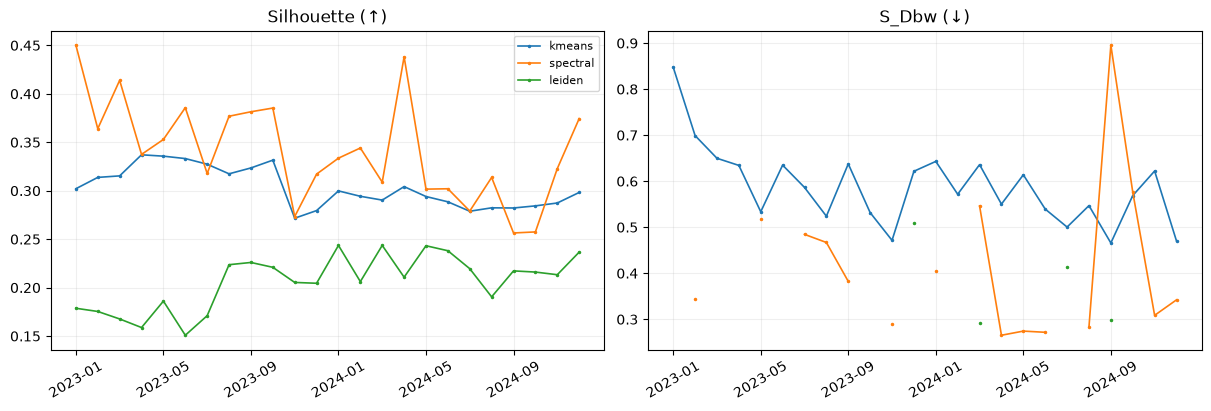

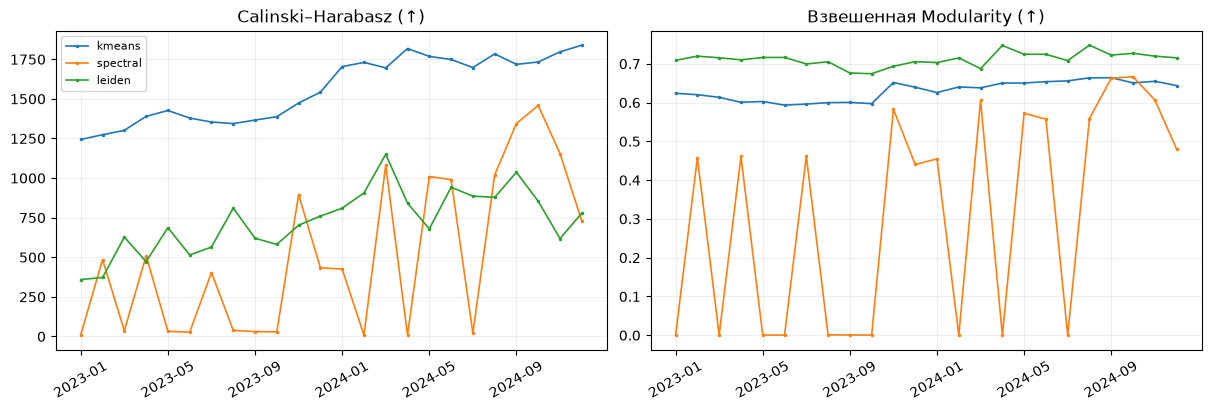

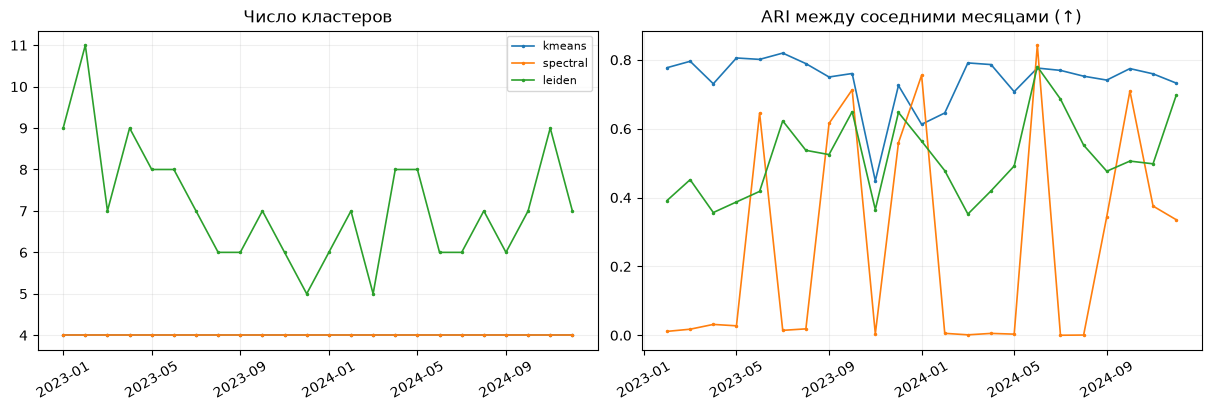

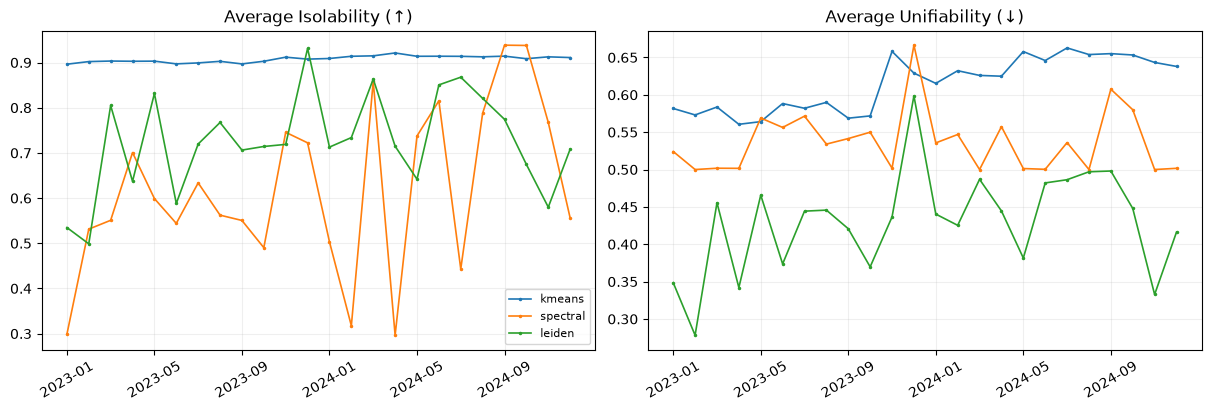

In [6]:
fig, _ = plot_quality_pairs(metrics09, 'sw', 's_dbw',
                           ('Silhouette (↑)', 'S_Dbw (↓)'))
plt.show()
fig, _ = plot_quality_pairs(metrics09, 'ch', 'modularity',
                           ('Calinski–Harabasz (↑)', 'Взвешенная Modularity (↑)'))
plt.show()
fig, _ = plot_quality_pairs(metrics09, 'n_clusters', 'ari_prev',
                           ('Число кластеров', 'ARI между соседними месяцами (↑)'))
plt.show()
fig, _ = plot_quality_pairs(metrics09, 'avi', 'avu',
                           ('Average Isolability (↑)', 'Average Unifiability (↓)'))
plt.show()

## 10. Интерпретационные ограничения

- **Геометрия:** все разбиения оцениваются на шести CLR-признаках. Это справедливое единое сравнение, но не независимое доказательство широких экономических типов. Годовые признаки БДМО требуют самостоятельной содержательной интерпретации на этапе 10.
- **Граф:** модулярность оценивается на одной и той же взвешенной сети. Она предпочтительнее для выявления сообществ, но не гарантирует компактности в CLR-пространстве.
- **Число сообществ:** CH, S_Dbw, Modularity и устойчивость чувствительны к $K$. Особенно осторожно трактуются одиночные сообщества Leiden.
- **Время:** высокий ARI/NMI между месяцами может означать как стабильную структуру, так и подавление реальных изменений регуляризацией. На этапе 08 фиксировалось ухудшение признакового соответствия при слишком большом $\lambda$.
- **Различие выборок SW:** ранее SW рассчитывался по случайной фиксированной подвыборке, теперь — по всем муниципалитетам; таблицы разных этапов нельзя напрямую сравнивать как одинаковые измерения.
- **Сетевые ICVI:** AVI и AVU рассчитаны строго по формулам (18)–(21) Shalileh и соавт. на бинарном графе; MQ принято как взвешенную модулярность Ньюмана–Гирвана. Официальное конкурсное соответствие последнего обозначения остаётся оговоркой.

## 11. Результаты оценки и научное заключение

### 11.1. Полнота и сопоставимость эксперимента

Оценены **четыре сохранённых алгоритма** — K-Means, Spectral Clustering, Leiden и Temporal K-Means — за **24 месяца (2023–2024 годы)**. Всего рассмотрено **96 разбиений** по **2016 муниципалитетам**. Метки и графы взяты из предыдущих этапов; повторное обучение не проводилось. Геометрические индексы SW, CH и S_Dbw вычислены в общем месячном CLR-пространстве; графовые AVI и AVU — на бинарной топологии одного и того же экономического графа; MQ — на его взвешенных рёбрах.

Расчёт **AVI, AVU и MQ завершён для всех 96 разбиений**, исключений выполнения нет. Проверка `MQ == modularity` дала `True`: при принятом определении это **два названия одного численного индекса**, а не независимые свидетельства качества.

Особое ограничение относится к **S_Dbw**: значения не определены для **20 из 24 месяцев Leiden** и **8 из 24 месяцев Spectral**. Пропуск S_Dbw не означает отсутствия SW, CH или остальных метрик за тот же месяц. Сравнивать выборочные медианы S_Dbw этих алгоритмов с полными 24-месячными медианами других методов как равнозначные оценки нельзя.

### 11.2. Итоговое сравнение по шести ICVI и временной согласованности

| Критерий (медиана по месяцам) | K-Means | Temporal K-Means | Leiden | Spectral |
|:--|--:|--:|--:|--:|
| **SW** ↑ | 0,299 | 0,296 | 0,212 | **0,336** |
| **CH** ↑ | **1619,136** | 1615,121 | 731,166 | 429,623 |
| **S_Dbw** ↓ | 0,579 (24/24) | 0,572 (24/24) | 0,357 (4/24) | 0,363 (16/24) |
| **AVI** ↑ | **0,909** | 0,905 | 0,717 | 0,581 |
| **AVU** ↓ | 0,625 | 0,619 | **0,442** | 0,535 |
| **MQ = Modularity Q** ↑ | 0,639 | 0,637 | **0,715** | 0,456 |
| ARI соседних месяцев ↑ | 0,760 | **0,848** | 0,498 | 0,028 |
| NMI соседних месяцев ↑ | 0,747 | **0,817** | 0,615 | 0,103 |
| Число кластеров | 4 | 4 | 7 | 4 |
| Доля крупнейшего кластера | 0,333 | 0,335 | 0,381 | 0,700 |

Значения S_Dbw в скобках сопровождаются **числом месяцев с определённым индексом**. Число кластеров и доля крупнейшего кластера представлены медианами. Стрелки обозначают принятое направление предпочтения внутри отдельного индекса; **единого среднего балла из несопоставимых метрик не строится**.

### 11.3. Различия методов и компромиссы

**K-Means.** Имеет наибольший медианный CH (**1619,136**) и AVI (**0,909**), при этом медианная доля крупнейшего кластера составляет **33,3%**. Относительная геометрическая компактность и высокая изолированность найденных типов сочетаются с умеренной модулярностью (**0,639**). По критериям пространственной разделимости и баланса размеров это сильная статическая базовая модель.

**Temporal K-Means ($\lambda=0{,}25$).** По сравнению с независимым K-Means временной ARI повышается с **0,760 до 0,848**, а NMI — с **0,747 до 0,817**. При этом геометрические и сетевые показатели почти не изменяются: SW **0,299 → 0,296**, CH **1619,136 → 1615,121**, AVI **0,909 → 0,905**, AVU **0,625 → 0,619**, MQ **0,639 → 0,637**. Следовательно, временная связь увеличивает согласованность траекторий без заметного разрушения исходной структуры кластеров. Но более высокий ARI **частично обусловлен самой регуляризацией** и не доказывает автоматически правильность каждого сохранённого или подавленного перехода.

**Leiden.** Лидирует по графовой модулярности (**MQ = 0,715**) и имеет минимальную медианную AVU (**0,442**), то есть сильнее разделяет графовые сообщества по двум сетевым критериям. Однако его AVI (**0,717**) и SW (**0,212**) уступают K-Means; число сообществ меняется от месяца к месяцу (медиана **7**). AVI и AVU зависят от числа кластеров и распределения связей, поэтому выигрыш Leiden по AVU при другом $K$ нельзя считать прямым доказательством превосходства при одинаковой детализации типологии. Дополнительно **S_Dbw определён лишь в 4 месяцах**, что ограничивает геометрическое сравнение.

**Spectral Clustering.** Максимальный медианный SW (**0,336**) не сопровождается сопоставимо хорошими остальными результатами: медианный CH **429,623**, AVI **0,581**, MQ **0,456**; крупнейшая группа охватывает **70,0%** муниципалитетов, а ARI между соседними месяцами составляет лишь **0,028**. Например, в январе 2023 года SW достигает **0,450** при CH **10,893** и MQ **0,000**. Такой контраст указывает, что высокий SW сам по себе не гарантирует полноценного разделения экономических типов или устойчивой сетевой структуры.

### 11.4. Разброс и календарные периоды

Новые сетевые индексы дополнительно подтверждают различие в стабильности качества. По AVI межквартильный размах (IQR) равен **0,011** для K-Means и Temporal K-Means, **0,143** для Leiden и **0,227** для Spectral. По MQ IQR составляет соответственно **0,049**, **0,049**, **0,016** и **0,562**. Таким образом, Leiden сохраняет относительно ровную графовую модулярность, но более переменный AVI; Spectral демонстрирует особенно выраженную неоднородность обоих сетевых показателей.

Для K-Means **лучший AVI** наблюдается в **апреле 2024 года**, **худший — в январе 2023 года**; для Temporal K-Means лучший AVI также приходится на **апрель 2024 года**, худший — на **сентябрь 2023 года**. Максимум MQ для обоих методов отмечен в **сентябре 2024 года**. По SW худший месяц у обоих — **ноябрь 2023 года**; для CH минимум приходится на **январь 2023 года**, максимум — на **декабрь 2024 года**. Эти даты характеризуют периоды изменения **качества разбиения**; сами по себе они не устанавливают причины экономических изменений.

### 11.5. Вывод и передача следующему этапу

**Один алгоритм не доминирует по всем критериям.** K-Means превосходит альтернативы по CH и AVI; Leiden — по MQ и AVU; Spectral — по SW, но формирует несбалансированные и плохо согласованные во времени разбиения; Temporal K-Means обеспечивает наибольшую временную согласованность среди рассматриваемых методов при почти неизменном геометрическом качестве относительно K-Means.

Для дальнейшего исследования экономической типологии обоснованно сохранить **Temporal K-Means ($K=4$, $\lambda=0{,}25$)** как основной *динамический кандидат*, **K-Means ($K=4$)** как статический контроль и **Leiden (resolution $=0{,}3$)** как графовую альтернативу. Это **многокритериальный выбор для следующего этапа**, а не доказательство глобального оптимума. Необходимо учитывать экономическую интерпретируемость типов, устойчивость к параметрам и фактическую динамику переходов.

Границы полученного результата: (1) MQ интерпретируется здесь как взвешенная модулярность Ньюмана–Гирвана, но точное соответствие конкурсной трактовке не подтверждено; (2) AVI/AVU вычислены на **бинарной** топологии, а MQ — на **взвешенном** графе; (3) сравнение AVI/AVU при разном числе сообществ требует осторожности; (4) S_Dbw не определён для существенной части разбиений Leiden/Spectral; (5) геометрические индексы характеризуют потребительские CLR-признаки, а не всю экономику муниципалитетов.

**Результат этапа:** одна воспроизводимая таблица `validation_metrics.parquet`, содержащая шесть ICVI (SW, CH, S_Dbw, AVI, AVU, MQ), дополнительные показатели и идентификаторы методов для всех 24 месяцев. Исходные графы и метки не пересчитывались и не дублировались.


## 12. Один итоговый файл и передача следующему этапу

Сохраняется **только** `validation_metrics.parquet`: по одной строке на месяц и метод, с идентификатором конфигурации, геометрическими, графовыми и временными показателями, признаковым и графовым пространствами. Уже имеющиеся графы и разбиения не дублируются; параметры и ограничения хранятся в секции `validation_09` общего JSON-конфига.

In [7]:
output = ROOT / vcfg['output_file']
result_path = save_metrics(output, metrics09)
print('Сохранена единственная таблица:',result_path.relative_to(ROOT))
print('Строк:',len(metrics09),'| методов:',metrics09.method.nunique(),
      '| месяцев:',metrics09.month.nunique())

Сохранена единственная таблица: outputs/bdmo_v3/validation_step09/validation_metrics.parquet
Строк: 72 | методов: 3 | месяцев: 24
